In [24]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [25]:
df = pd.read_csv("diamonds.csv")
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [26]:
df.shape

(53940, 10)

In [27]:
df = df.drop_duplicates()
df = df.dropna()
df.shape

(53794, 10)

In [28]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
carat,53794.0,0.797780,0.473390,0.2,0.40,0.70,1.04,5.01
depth,53794.0,61.748080,1.429909,43.0,61.00,61.80,62.50,79.00
table,53794.0,57.458109,2.233679,43.0,56.00,57.00,59.00,95.00
price,53794.0,3933.065082,3988.114460,326.0,951.00,2401.00,5326.75,18823.00
x,53794.0,5.731214,1.120695,0.0,4.71,5.70,6.54,10.74
y,53794.0,5.734653,1.141209,0.0,4.72,5.71,6.54,58.90
z,53794.0,3.538714,0.705037,0.0,2.91,3.53,4.03,31.80


In [29]:
print(df['cut'].unique())
print(df['color'].unique())
print(df['clarity'].unique())

['Ideal' 'Premium' 'Good' 'Very Good' 'Fair']
['E' 'I' 'J' 'H' 'F' 'G' 'D']
['SI2' 'SI1' 'VS1' 'VS2' 'VVS2' 'VVS1' 'I1' 'IF']


In [30]:
cut_map = {"Fair": 1, "Good": 2, "Very Good": 3, "Premium": 4, "Ideal": 5}
color_map = {"J": 1, "I": 2, "H": 3, "G": 4, "F": 5, "E": 6, "D": 7}
clarity_map = {
    "I1": 1,
    "SI2": 2,
    "SI1": 3,
    "VS2": 4,
    "VS1": 5,
    "VVS2": 6,
    "VVS1": 7,
    "IF": 8,
}

In [31]:
df["cut"] = df["cut"].map(cut_map).astype(int)
df["color"] = df["color"].map(color_map).astype(int)
df["clarity"] = df["clarity"].map(clarity_map).astype(int)

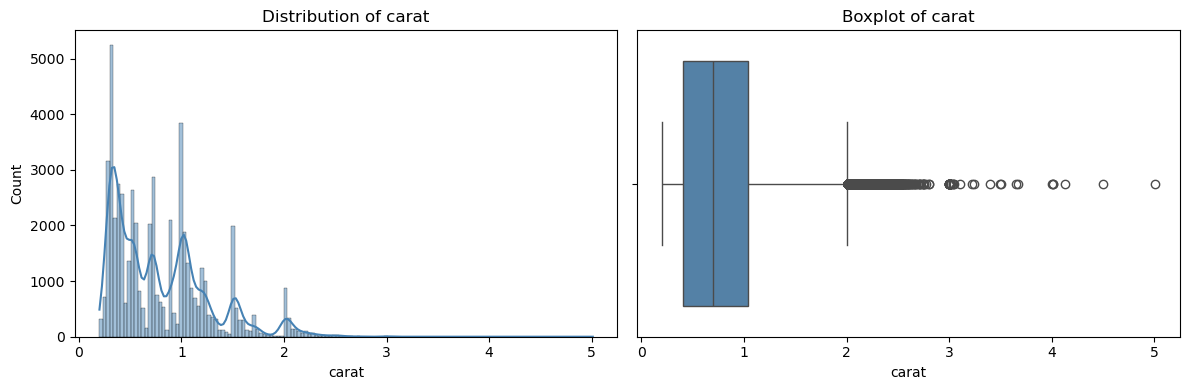

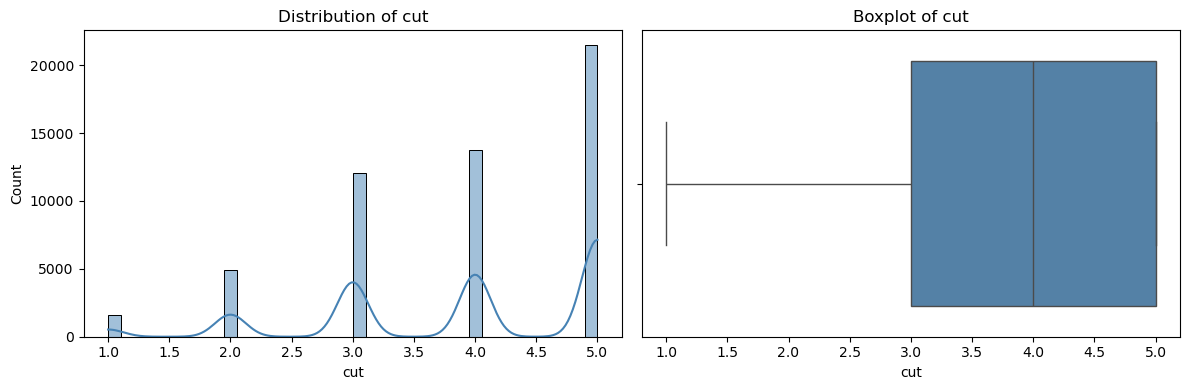

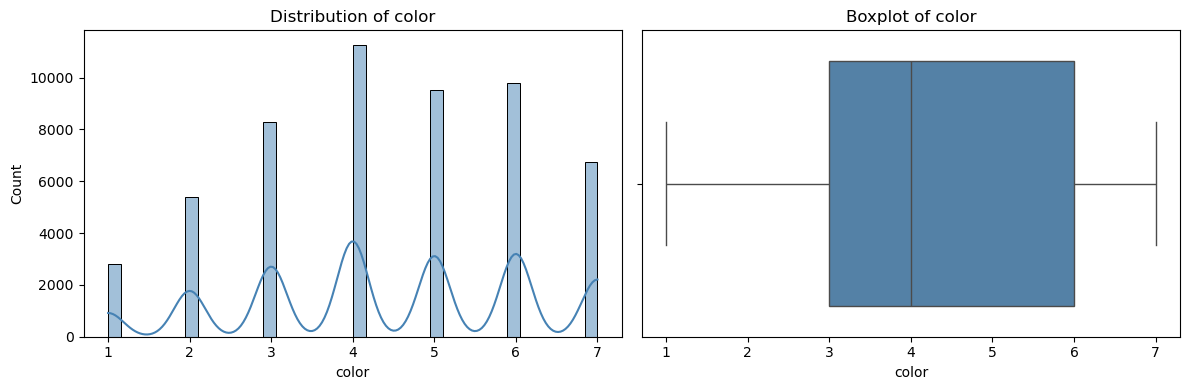

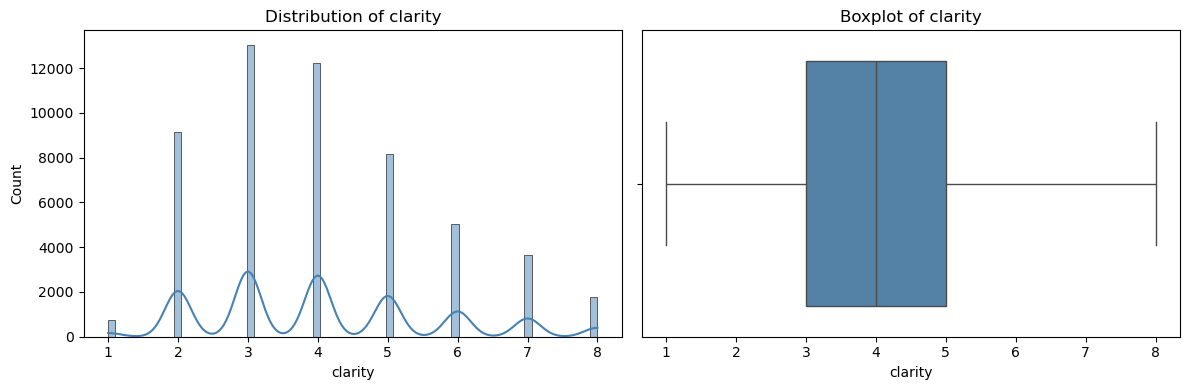

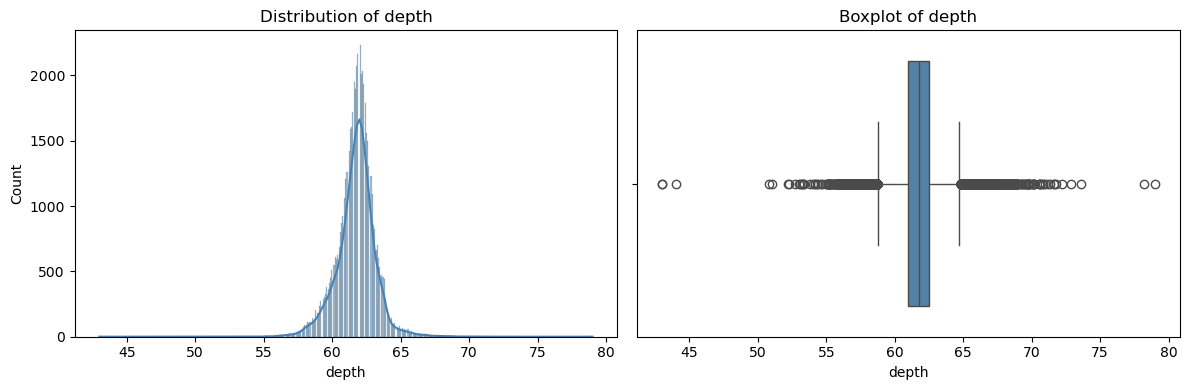

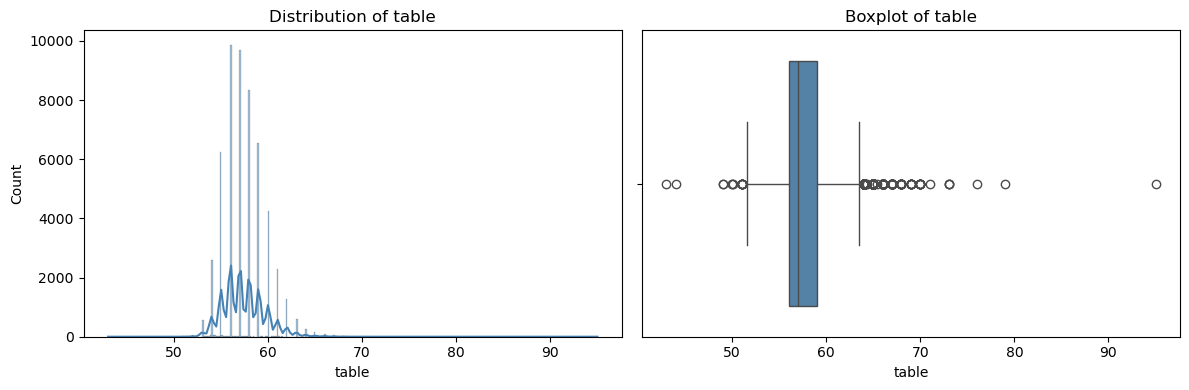

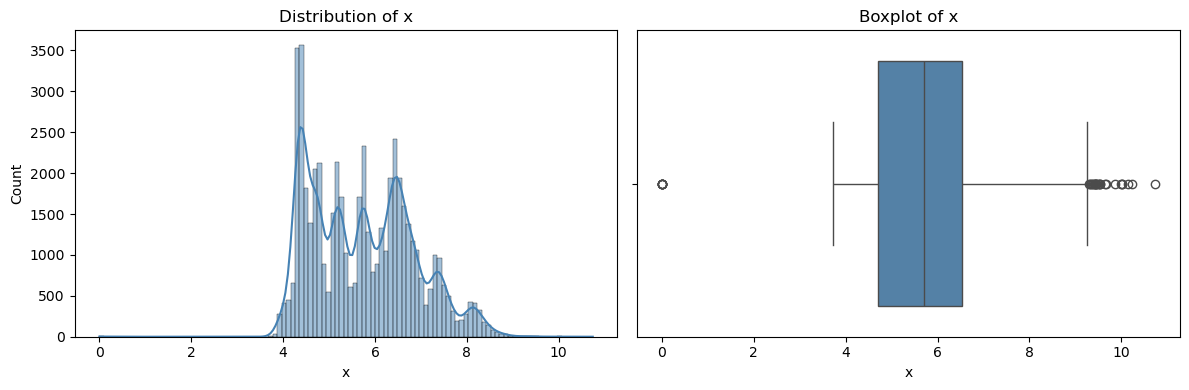

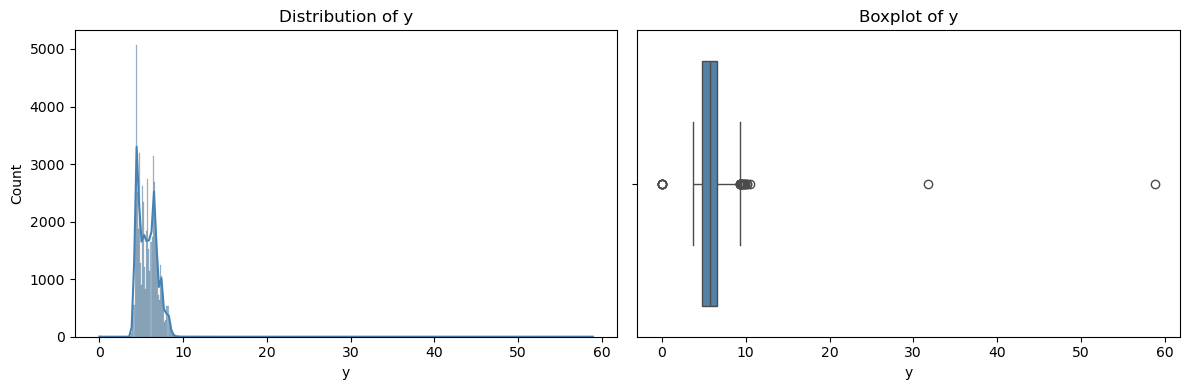

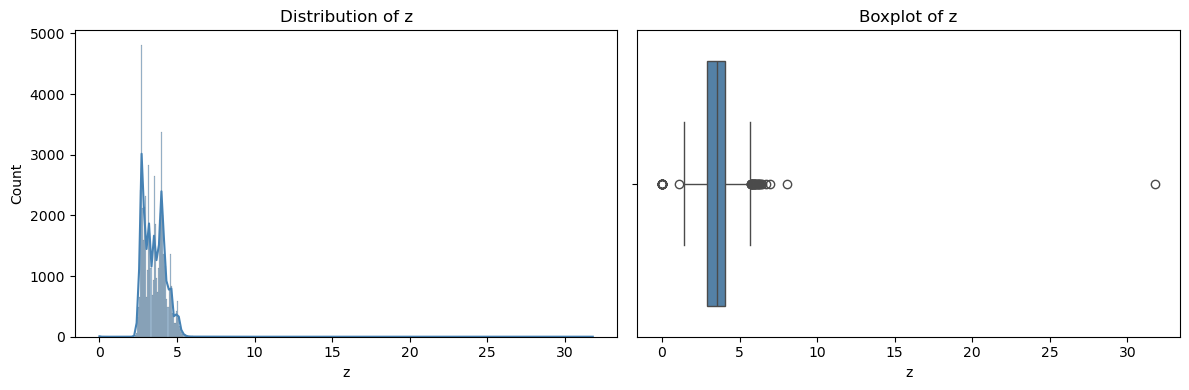

In [32]:
numerical_cols = df.columns.drop('price')

for col in numerical_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(df[col], kde=True, ax=axes[0], color="steelblue")
    sns.boxplot(x=df[col], ax=axes[1], color="steelblue")
    axes[0].set_title(f"Distribution of {col}")
    axes[1].set_title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()

In [33]:
X = df.drop(columns=["price"])
y = df["price"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [34]:
input_shape = (X_train.shape[1],) 
print(input_shape)

(9,)


In [35]:
model = keras.Sequential(
    [
        layers.Input(shape=input_shape),
        # Hidden Layer 1
        layers.Dense(128, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        # Hidden Layer 2
        layers.Dense(128, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        # Hidden Layer 3
        layers.Dense(64, activation="relu"),
        layers.BatchNormalization(),
        # Output Layer: 1 neuron for continuous dollar price
        layers.Dense(1),
    ]
)

In [36]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 128)            │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,393 (107.00 KB)

 Trainable params: 26,753 (104.50 KB)

 Non-trainable params: 640 (2.50 KB)

In [37]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.002),
    loss="mae",  # Minimizes absolute dollar difference directly
    metrics=["mae"],
)

In [38]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
)

In [39]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    batch_size=256,  # Larger batch size because dataset is larger (~54k rows)
    epochs=100,
    callbacks=[early_stopping],
    verbose=1,
)
# ==============================================================================
# 6. Evaluate and Test Predictions
# ==============================================================================
test_mae = model.evaluate(X_test, y_test, verbose=0)[0]
print(f"\nFinal Test MAE: ${test_mae:.2f}")
# Compare actual vs predicted on first 5 samples
preds = model.predict(X_test[:5])
print("\n--- Sample Predictions ---")
for actual, pred in zip(y_test[:5], preds.flatten()):
    print(
        f"Actual: ${actual:,.2f} | Predicted: ${pred:,.2f} | Diff:"
        f" ${abs(actual - pred):,.2f}"
    )

Epoch 1/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 3930.2153 - mae: 3930.2153 - val_loss: 3978.7615 - val_mae: 3978.7615
Epoch 2/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3906.9966 - mae: 3906.9966 - val_loss: 3945.1633 - val_mae: 3945.1633
Epoch 3/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3858.7400 - mae: 3858.7400 - val_loss: 3884.0361 - val_mae: 3884.0361
Epoch 4/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3786.0210 - mae: 3786.0210 - val_loss: 3800.9973 - val_mae: 3800.9973
Epoch 5/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3690.0266 - mae: 3690.0266 - val_loss: 3657.9717 - val_mae: 3657.9717
Epoch 6/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3571.9226 - mae: 3571.9226 - val_loss: 3581.9348 - val_mae: 3581.9348
Epoch 7/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3432.8208 - mae: 3432.8208 - val_loss: 3355.9592 - val_mae: 3355.9592
Epoch 8/100
135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3273.6531 - mae: 3273.

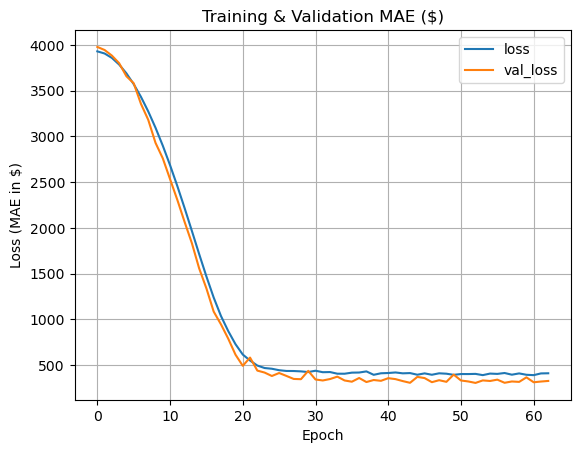

In [40]:
# ==============================================================================
# 7. Plot Loss Curves (Learning Curves)
# ==============================================================================
history_df = pd.DataFrame(history.history)
history_df[["loss", "val_loss"]].plot(title="Training & Validation MAE ($)")
plt.xlabel("Epoch")
plt.ylabel("Loss (MAE in $)")
plt.grid(True)
plt.show()

In [41]:
from sklearn.metrics import r2_score

# Get predictions
preds = model.predict(X_test).flatten()

# 1. R-squared Score (Overall quality of fit, max 1.0)
r2 = r2_score(y_test, preds)
print(f"R² Score: {r2:.4f}  (Explains {r2 * 100:.1f}% of price variance)")

# 2. Mean Absolute Percentage Error (MAPE)
mape = np.mean(np.abs((y_test - preds) / y_test)) * 100
print(f"MAPE: {mape:.2f}%  (Average prediction is within {mape:.1f}% of price)")

# 3. "Tolerance Accuracy" (How many predictions are within ±10% of true price)
within_10_percent = np.mean(np.abs((y_test - preds) / y_test) <= 0.10) * 100
within_20_percent = np.mean(np.abs((y_test - preds) / y_test) <= 0.20) * 100

print(f"Predictions within ±10%: {within_10_percent:.1f}%")
print(f"Predictions within ±20%: {within_20_percent:.1f}%")

337/337 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
R² Score: 0.9804  (Explains 98.0% of price variance)
MAPE: 8.24%  (Average prediction is within 8.2% of price)
Predictions within ±10%: 70.3%
Predictions within ±20%: 92.0%
